In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("health_dataset.csv")
original_df = df.copy()
print("Dataset shape:", df.shape)
display(df.head())
display(df.tail())


Dataset shape: (2500, 13)


,Patient_ID,Age,Gender,Smoking_Status,Years_of_Smoking,Cigarettes_Per_Day,Organ,Organ_Condition,BMI,BP_Risk,Cholesterol_Level,Family_History_Risk,Alcohol_Consumption
0,1,32,Male,Never,0,0,Liver,Healthy,28.1,Low,202.7,No,Low
1,2,47,Female,Former,2,8,Lungs,Healthy,21.6,Normal,214.5,No,Low
2,3,77,Female,Former,10,12,Heart,Healthy,41.6,Normal,274.8,No,Low
3,4,77,Female,Never,0,0,Lungs,Healthy,17.4,Normal,163.4,No,Moderate
4,5,53,Female,Current,39,18,Kidney,Healthy,30.0,Normal,153.3,No,Moderate


,Patient_ID,Age,Gender,Smoking_Status,Years_of_Smoking,Cigarettes_Per_Day,Organ,Organ_Condition,BMI,BP_Risk,Cholesterol_Level,Family_History_Risk,Alcohol_Consumption
2495,2496,59,Male,Never,0,0,Human Body,Damaged,31.0,Normal,193.8,No,Low
2496,2497,69,Female,Never,0,0,Kidney,Healthy,24.2,Normal,210.4,No,Moderate
2497,2498,43,Male,Current,13,16,Heart,Healthy,39.9,Low,128.7,No,Moderate
2498,2499,43,Female,Current,15,6,Human Body,Healthy,41.2,Normal,129.3,Yes,Low
2499,2500,49,Male,Never,0,0,Lungs,Healthy,33.8,Low,129.7,No,High


In [5]:
df.info()
print("\\nColumn names:", df.columns.tolist())
print("\\nData types:")
display(df.dtypes.to_frame("Data Type"))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Patient_ID           2500 non-null   int64  
 1   Age                  2500 non-null   int64  
 2   Gender               2500 non-null   object 
 3   Smoking_Status       2500 non-null   object 
 4   Years_of_Smoking     2500 non-null   int64  
 5   Cigarettes_Per_Day   2500 non-null   int64  
 6   Organ                2500 non-null   object 
 7   Organ_Condition      2500 non-null   object 
 8   BMI                  2500 non-null   float64
 9   BP_Risk              2500 non-null   object 
 10  Cholesterol_Level    2500 non-null   float64
 11  Family_History_Risk  2500 non-null   object 
 12  Alcohol_Consumption  2500 non-null   object 
dtypes: float64(2), int64(4), object(7)
memory usage: 254.0+ KB
\nColumn names: ['Patient_ID', 'Age', 'Gender', 'Smoking_Status', 'Years_of_Smo

,Data Type
Patient_ID,int64
Age,int64
Gender,object
Smoking_Status,object
Years_of_Smoking,int64
Cigarettes_Per_Day,int64
Organ,object
Organ_Condition,object
BMI,float64
BP_Risk,object


In [6]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)
display(df[num_cols].describe())
display(df[cat_cols].describe())


Numerical columns: ['Patient_ID', 'Age', 'Years_of_Smoking', 'Cigarettes_Per_Day', 'BMI', 'Cholesterol_Level']
Categorical columns: ['Gender', 'Smoking_Status', 'Organ', 'Organ_Condition', 'BP_Risk', 'Family_History_Risk', 'Alcohol_Consumption']


,Patient_ID,Age,Years_of_Smoking,Cigarettes_Per_Day,BMI,Cholesterol_Level
count,2500.00000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,1250.50000,54.031600,8.976800,6.833200,29.620680,207.785600
std,721.83216,20.793738,11.155144,8.341583,7.239672,52.852446
min,1.00000,18.000000,0.000000,0.000000,17.000000,120.000000
25%,625.75000,36.000000,0.000000,0.000000,23.600000,161.700000
50%,1250.50000,54.000000,4.000000,3.000000,29.400000,206.650000
75%,1875.25000,72.000000,16.000000,12.000000,35.900000,253.625000
max,2500.00000,89.000000,39.000000,29.000000,42.000000,300.000000


,Gender,Smoking_Status,Organ,Organ_Condition,BP_Risk,Family_History_Risk,Alcohol_Consumption
count,2500,2500,2500,2500,2500,2500,2500
unique,2,3,5,2,3,2,3
top,Male,Never,Liver,Healthy,Normal,No,Low
freq,1262,1136,549,1603,1396,1758,1233


In [7]:
missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})
display(missing_report)
print("Exact duplicate rows:", df.duplicated().sum())


,Missing Count,Missing Percentage
Patient_ID,0,0.0
Age,0,0.0
Gender,0,0.0
Smoking_Status,0,0.0
Years_of_Smoking,0,0.0
Cigarettes_Per_Day,0,0.0
Organ,0,0.0
Organ_Condition,0,0.0
BMI,0,0.0
BP_Risk,0,0.0


Exact duplicate rows: 0


In [8]:
data = original_df.copy()

# Trim leading/trailing spaces in categorical values
for col in data.select_dtypes(include="object").columns:
    data[col] = data[col].str.strip()

# Impute only columns that actually contain missing values
for col in data.select_dtypes(include=np.number).columns:
    if data[col].isna().any():
        data[col] = data[col].fillna(data[col].median())

for col in data.select_dtypes(include="object").columns:
    if data[col].isna().any():
        data[col] = data[col].fillna(data[col].mode()[0])

before_duplicates = len(data)
data = data.drop_duplicates().copy()
print("Rows removed as exact duplicates:", before_duplicates - len(data))
print("Missing values after handling:", int(data.isna().sum().sum()))
print("Remaining duplicate rows:", int(data.duplicated().sum()))


Rows removed as exact duplicates: 0
Missing values after handling: 0
Remaining duplicate rows: 0


In [9]:
for col in data.select_dtypes(include="object").columns:
    print(f"\\n{col}")
    display(data[col].value_counts())


\nGender


,count
Gender,
Male,1262
Female,1238


\nSmoking_Status


,count
Smoking_Status,
Never,1136
Current,733
Former,631


\nOrgan


...

,count
BP_Risk,
Normal,1396
High,629
Low,475


\nFamily_History_Risk


,count
Family_History_Risk,
No,1758
Yes,742


\nAlcohol_Consumption


,count
Alcohol_Consumption,
Low,1233
Moderate,911
High,356


In [10]:
display(data[["Age", "Years_of_Smoking", "Cigarettes_Per_Day", "BMI", "Cholesterol_Level"]].describe())


,Age,Years_of_Smoking,Cigarettes_Per_Day,BMI,Cholesterol_Level
count,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,54.031600,8.976800,6.833200,29.620680,207.785600
std,20.793738,11.155144,8.341583,7.239672,52.852446
min,18.000000,0.000000,0.000000,17.000000,120.000000
25%,36.000000,0.000000,0.000000,23.600000,161.700000
50%,54.000000,4.000000,3.000000,29.400000,206.650000
75%,72.000000,16.000000,12.000000,35.900000,253.625000
max,89.000000,39.000000,29.000000,42.000000,300.000000


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

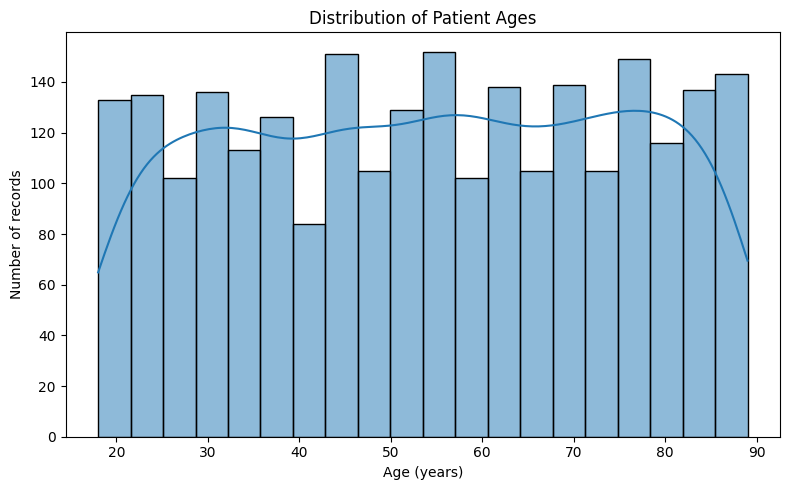

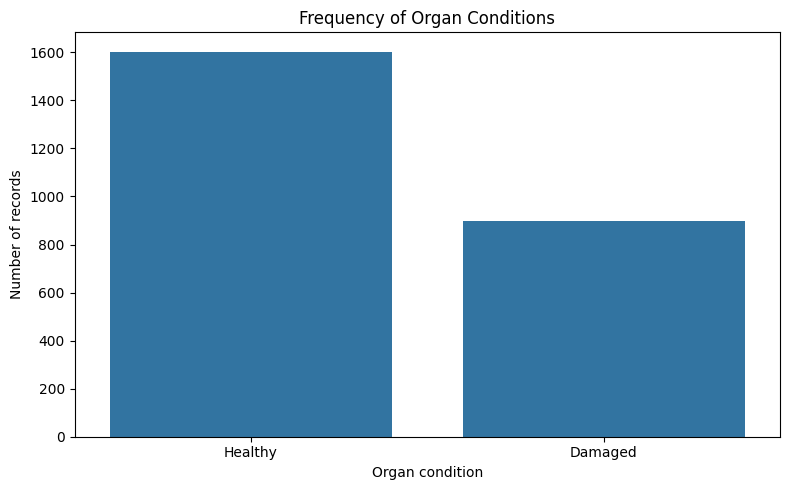

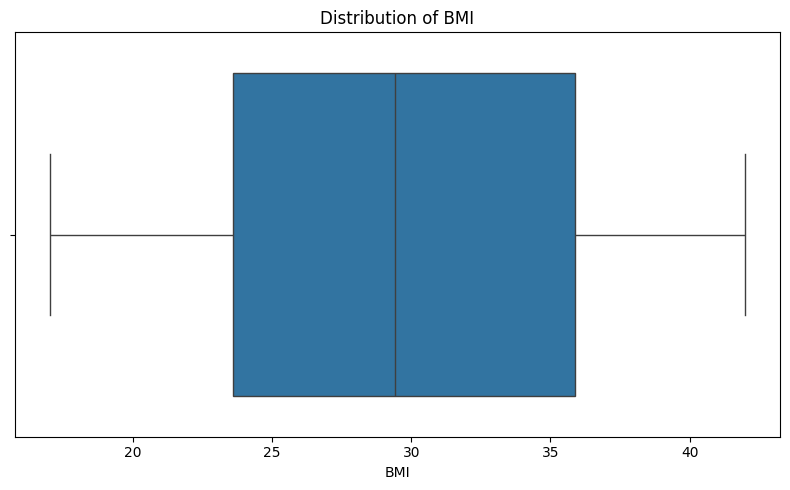

In [11]:
plt.figure(figsize=(8, 5))
sns.histplot(data=data, x="Age", bins=20, kde=True)
plt.title("Distribution of Patient Ages")
plt.xlabel("Age (years)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.countplot(data=data, x="Organ_Condition")
plt.title("Frequency of Organ Conditions")
plt.xlabel("Organ condition")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="BMI")
plt.title("Distribution of BMI")
plt.xlabel("BMI")
plt.tight_layout()
plt.show()


In [12]:
categorical_cols = data.select_dtypes(include="object").columns.tolist()
encoded = pd.get_dummies(data, columns=categorical_cols, drop_first=True, dtype=int)
print("Before encoding:", data.shape)
print("After encoding:", encoded.shape)
display(encoded.head())


Before encoding: (2500, 13)
After encoding: (2500, 19)


,Patient_ID,Age,Years_of_Smoking,Cigarettes_Per_Day,BMI,Cholesterol_Level,Gender_Male,Smoking_Status_Former,Smoking_Status_Never,Organ_Human Body,Organ_Kidney,Organ_Liver,Organ_Lungs,Organ_Condition_Healthy,BP_Risk_Low,BP_Risk_Normal,Family_History_Risk_Yes,Alcohol_Consumption_Low,Alcohol_Consumption_Moderate
0,1,32,0,0,28.1,202.7,1,0,1,0,0,1,0,1,1,0,0,1,0
1,2,47,2,8,21.6,214.5,0,1,0,0,0,0,1,1,0,1,0,1,0
2,3,77,10,12,41.6,274.8,0,1,0,0,0,0,0,1,0,1,0,1,0
3,4,77,0,0,17.4,163.4,0,0,1,0,0,0,1,1,0,1,0,0,1
4,5,53,39,18,30.0,153.3,0,0,0,0,1,0,0,1,0,1,0,0,1


In [13]:
scale_cols = [c for c in ["Age", "Years_of_Smoking", "Cigarettes_Per_Day", "BMI", "Cholesterol_Level"] if c in encoded.columns]
scaler = StandardScaler()
encoded[scale_cols] = scaler.fit_transform(encoded[scale_cols])
print("Scaled columns:", scale_cols)
display(encoded.head())


Scaled columns: ['Age', 'Years_of_Smoking', 'Cigarettes_Per_Day', 'BMI', 'Cholesterol_Level']


,Patient_ID,Age,Years_of_Smoking,Cigarettes_Per_Day,BMI,Cholesterol_Level,Gender_Male,Smoking_Status_Former,Smoking_Status_Never,Organ_Human Body,Organ_Kidney,Organ_Liver,Organ_Lungs,Organ_Condition_Healthy,BP_Risk_Low,BP_Risk_Normal,Family_History_Risk_Yes,Alcohol_Consumption_Low,Alcohol_Consumption_Moderate
0,1,-1.059742,-0.804884,-0.819337,-0.210090,-0.096242,1,0,1,0,0,1,0,1,1,0,0,1,0
1,2,-0.338227,-0.625559,0.139906,-1.108101,0.127066,0,1,0,0,0,0,1,1,0,1,0,1,0
2,3,1.104804,0.091743,0.619527,1.655008,1.268206,0,1,0,0,0,0,0,1,0,1,0,1,0
3,4,1.104804,-0.804884,-0.819337,-1.688353,-0.839970,0,0,1,0,0,0,1,1,0,1,0,0,1
4,5,-0.049621,2.691960,1.338959,0.052405,-1.031106,0,0,0,0,1,0,0,1,0,1,0,0,1


In [14]:
print("Final shape:", encoded.shape)
print("Remaining missing values:", int(encoded.isna().sum().sum()))
print("Remaining duplicate rows:", int(encoded.duplicated().sum()))
display(encoded.head())
encoded.to_csv("health_dataset_prepared.csv", index=False)
print("Saved: health_dataset_prepared.csv")


Final shape: (2500, 19)
Remaining missing values: 0
Remaining duplicate rows: 0


,Patient_ID,Age,Years_of_Smoking,Cigarettes_Per_Day,BMI,Cholesterol_Level,Gender_Male,Smoking_Status_Former,Smoking_Status_Never,Organ_Human Body,Organ_Kidney,Organ_Liver,Organ_Lungs,Organ_Condition_Healthy,BP_Risk_Low,BP_Risk_Normal,Family_History_Risk_Yes,Alcohol_Consumption_Low,Alcohol_Consumption_Moderate
0,1,-1.059742,-0.804884,-0.819337,-0.210090,-0.096242,1,0,1,0,0,1,0,1,1,0,0,1,0
1,2,-0.338227,-0.625559,0.139906,-1.108101,0.127066,0,1,0,0,0,0,1,1,0,1,0,1,0
2,3,1.104804,0.091743,0.619527,1.655008,1.268206,0,1,0,0,0,0,0,1,0,1,0,1,0
3,4,1.104804,-0.804884,-0.819337,-1.688353,-0.839970,0,0,1,0,0,0,1,1,0,1,0,0,1
4,5,-0.049621,2.691960,1.338959,0.052405,-1.031106,0,0,0,0,1,0,0,1,0,1,0,0,1


Saved: health_dataset_prepared.csv
